In [21]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.preprocessing import StandardScaler, RobustScaler

In [23]:
cols_names=[
'fLength'
,'fWidth'
,'fSize'
,'fConc'
,'fConc1'
,'fAsym'
,'fM3Long'
,'fM3Trans'
,'fAlpha'
,'fDist'
,'class']

In [24]:
df =pd.read_csv('magic04.data',names=cols_names)
df.head()

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


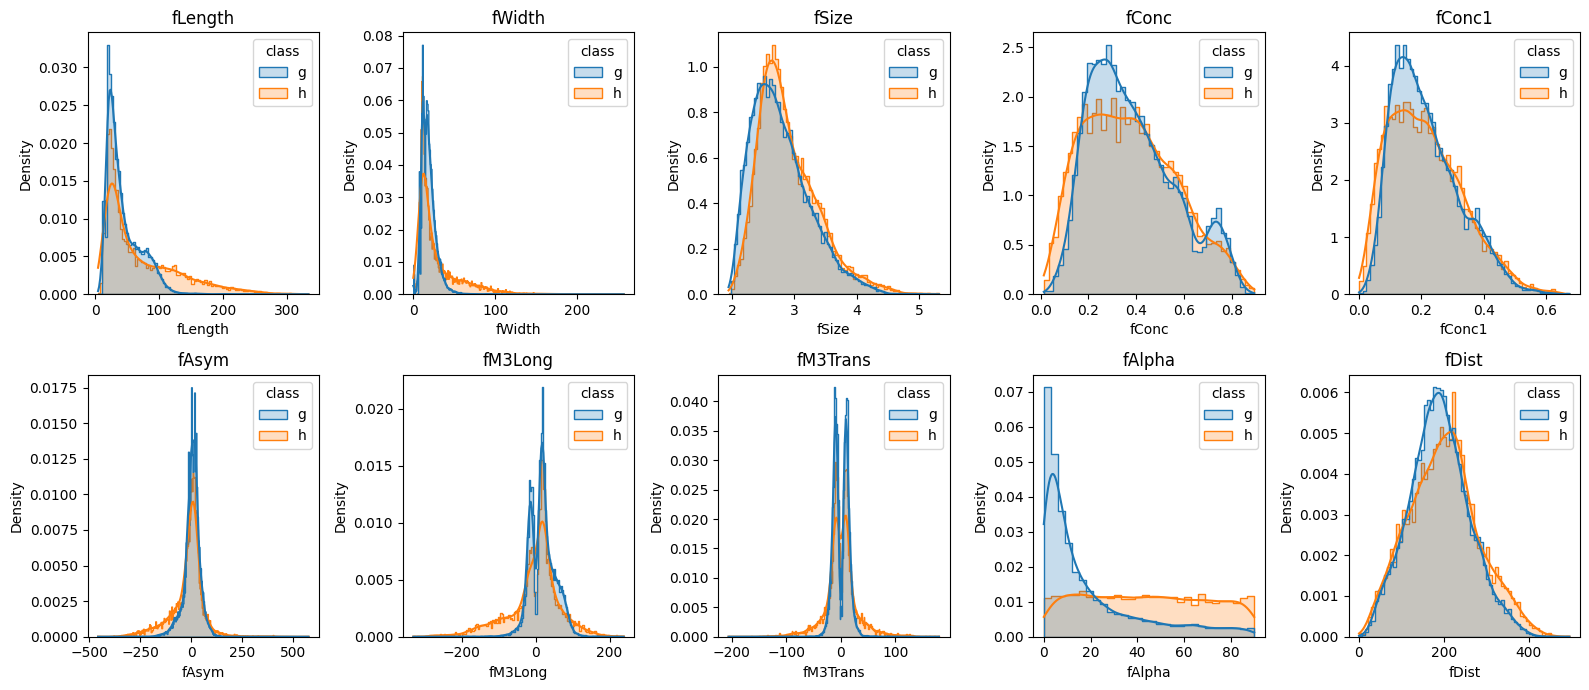

In [25]:
numeric_features = columns[:-1]

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for feature, ax in zip(numeric_features, axes.ravel()):
    sns.histplot(data=df, x=feature, hue='class', kde=True, stat='density',
                 common_norm=False, element='step', ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

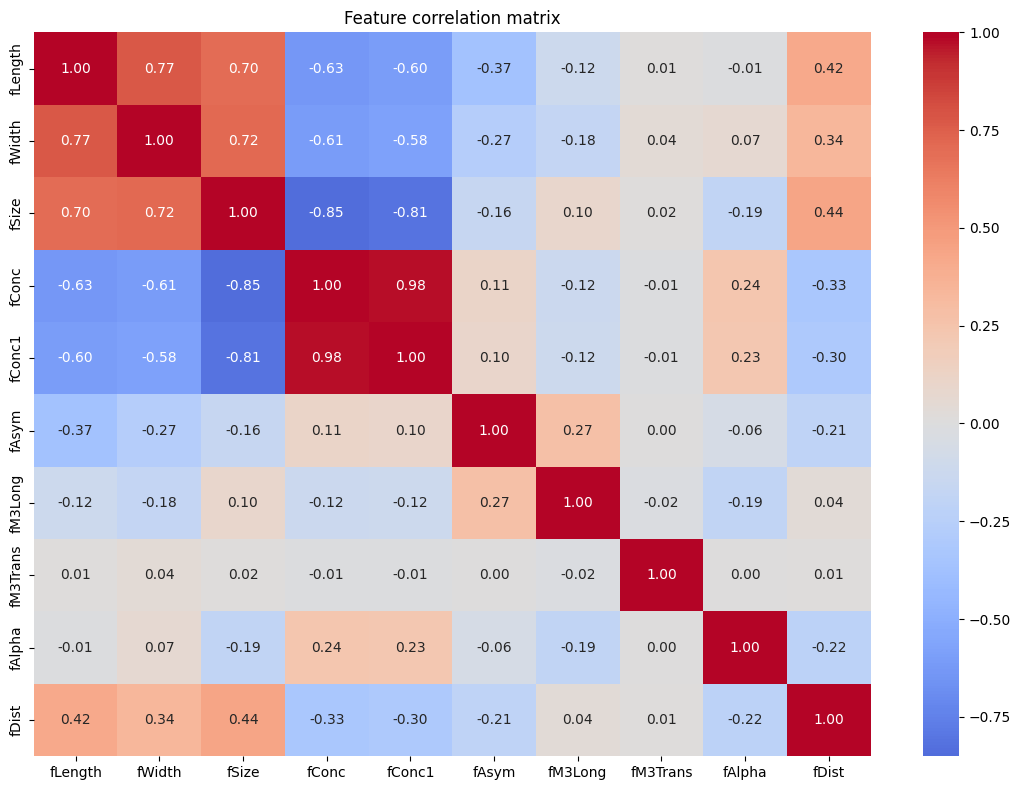

In [26]:
correlations = df[numeric_features].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature correlation matrix')
plt.tight_layout()
plt.show()

In [27]:
X = df.drop(columns='class')
y = df['class'].map({'g': 0, 'h': 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print('Training shape:', X_train.shape)
print('Test shape:', X_test.shape)
print('Training class proportions:')
display(y_train.value_counts(normalize=True).rename_axis('class').to_frame('proportion'))

Training shape: (15216, 10)
Test shape: (3804, 10)
Training class proportions:


,proportion
class,
0,0.648396
1,0.351604


In [28]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features)
])

model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=3000, random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [29]:
baseline_search = GridSearchCV(
    model_pipeline,
    param_grid={'model__C': [1.0], 'model__solver': ['lbfgs'], 'model__penalty': ['l2']},
    scoring='f1',
    cv=cv,
    n_jobs=-1
)
baseline_search.fit(X_train, y_train)
print('Baseline mean CV F1:', round(baseline_search.best_score_, 4))

Baseline mean CV F1: 0.6595


c:\Users\Asus\Downloads\nti 1\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [30]:
param_grid = [
    {
        'model__solver': ['liblinear'],
        'model__penalty': ['l1', 'l2'],
        'model__C': [0.01, 0.1, 1, 10, 100]
    },
    {
        'model__solver': ['lbfgs'],
        'model__penalty': ['l2'],
        'model__C': [0.01, 0.1, 1, 10, 100]
    }
]

grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)
grid_search.fit(X_train, y_train)
print('GridSearchCV best parameters:', grid_search.best_params_)
print('GridSearchCV best mean CV F1:', round(grid_search.best_score_, 4))

GridSearchCV best parameters: {'model__C': 1, 'model__penalty': 'l1', 'model__solver': 'liblinear'}
GridSearchCV best mean CV F1: 0.6597


c:\Users\Asus\Downloads\nti 1\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Asus\Downloads\nti 1\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


In [31]:
random_distributions = [
    {
        'model__solver': ['liblinear'],
        'model__penalty': ['l1', 'l2'],
        'model__C': np.logspace(-3, 3, 40)
    },
    {
        'model__solver': ['lbfgs'],
        'model__penalty': ['l2'],
        'model__C': np.logspace(-3, 3, 40)
    }
]

random_search = RandomizedSearchCV(
    estimator=model_pipeline,
    param_distributions=random_distributions,
    n_iter=20,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    random_state=42,
    return_train_score=True
)
random_search.fit(X_train, y_train)
print('RandomizedSearchCV best parameters:', random_search.best_params_)
print('RandomizedSearchCV best mean CV F1:', round(random_search.best_score_, 4))

c:\Users\Asus\Downloads\nti 1\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Asus\Downloads\nti 1\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


RandomizedSearchCV best parameters: {'model__solver': 'liblinear', 'model__penalty': 'l1', 'model__C': np.float64(0.5878016072274912)}
RandomizedSearchCV best mean CV F1: 0.66


In [32]:
results = pd.DataFrame([
    {
        'search': 'GridSearchCV',
        'best_cv_f1': grid_search.best_score_,
        'best_params': grid_search.best_params_
    },
    {
        'search': 'RandomizedSearchCV',
        'best_cv_f1': random_search.best_score_,
        'best_params': random_search.best_params_
    }
])
display(results[['search', 'best_cv_f1']])

,search,best_cv_f1
0,GridSearchCV,0.659679
1,RandomizedSearchCV,0.660034


In [33]:
best_search = max(
    [grid_search, random_search],
    key=lambda search: search.best_score_
)
best_model = best_search.best_estimator_
y_pred = best_model.predict(X_test)
y_probability = best_model.predict_proba(X_test)[:, 1]

print('Selected model:', type(best_search).__name__)
print('Test F1:', round(f1_score(y_test, y_pred), 4))
print('Test ROC-AUC:', round(roc_auc_score(y_test, y_probability), 4))
print('\nClassification report:')
print(classification_report(y_test, y_pred, target_names=['g', 'h']))

Selected model: RandomizedSearchCV
Test F1: 0.6798
Test ROC-AUC: 0.8468

Classification report:
              precision    recall  f1-score   support

           g       0.81      0.90      0.85      2466
           h       0.77      0.61      0.68      1338

    accuracy                           0.80      3804
   macro avg       0.79      0.76      0.77      3804
weighted avg       0.80      0.80      0.79      3804



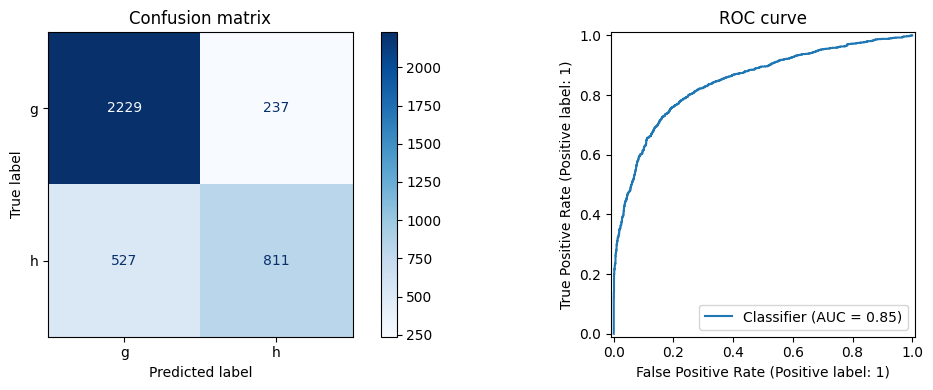

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['g', 'h'], cmap='Blues', ax=axes[0]
)
axes[0].set_title('Confusion matrix')

RocCurveDisplay.from_predictions(y_test, y_probability, ax=axes[1])
axes[1].set_title('ROC curve')
plt.tight_layout()
plt.show()

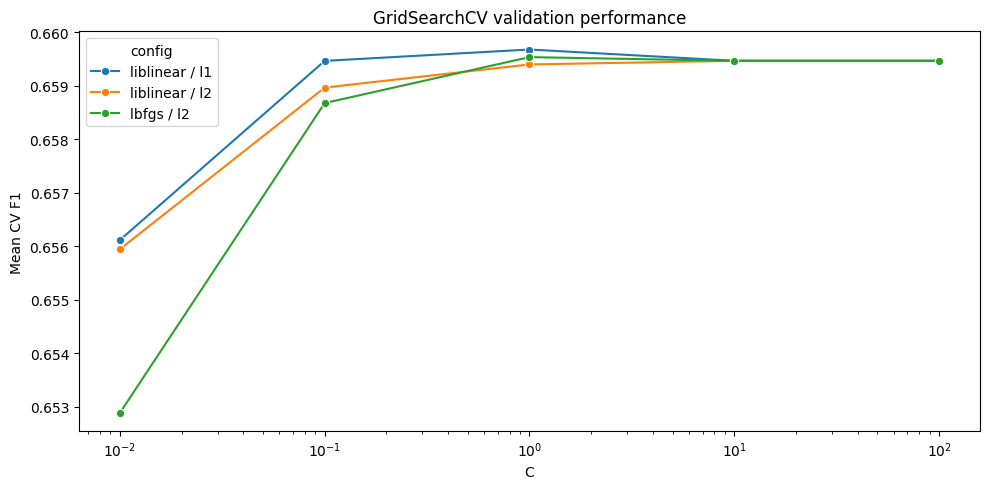

In [35]:
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results['config'] = (
    cv_results['param_model__solver'].astype(str)
    + ' / '
    + cv_results['param_model__penalty'].astype(str)
)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=cv_results,
    x='param_model__C',
    y='mean_test_score',
    hue='config',
    marker='o'
)
plt.xscale('log')
plt.ylabel('Mean CV F1')
plt.xlabel('C')
plt.title('GridSearchCV validation performance')
plt.tight_layout()
plt.show()